In [38]:
import pandas as pd
import numpy as np

In [39]:
import os
path = '../data/job-board-applications.csv' if os.path.exists('../data/job-board-applications.csv') else 'data/job-board-applications.csv'

df = pd.read_csv(path)
print(f"Shape: {df.shape}")
df.head()

Shape: (1206, 11)


,application_id,applied_on,role_category,work_mode,stipend_inr_month,source,steps_done,shortlisted,interviewed,hired,days_to_first_reply
0,A100010,2026-07-01,Software,on_site,30000,search,2,no,no,no,1.0
1,A100017,2026-07-01,Design,hybrid,0,search,2,no,no,no,9.0
2,A100102,2026-07-01,Operations,hybrid,0,search,0,no,no,no,3.0
3,A100319,2026-07-01,Marketing,remote,15000,search,4,no,no,no,4.0
4,A100394,2026-07-01,Software,on_site,10000,search,4,yes,no,no,2.0


In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1206 entries, 0 to 1205
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   application_id       1206 non-null   str    
 1   applied_on           1206 non-null   str    
 2   role_category        1206 non-null   str    
 3   work_mode            1206 non-null   str    
 4   stipend_inr_month    1206 non-null   int64  
 5   source               1191 non-null   str    
 6   steps_done           1206 non-null   int64  
 7   shortlisted          1206 non-null   str    
 8   interviewed          1206 non-null   str    
 9   hired                1206 non-null   str    
 10  days_to_first_reply  970 non-null    float64
dtypes: float64(1), int64(2), str(8)
memory usage: 103.8 KB


In [41]:
df.describe()

,stipend_inr_month,steps_done,days_to_first_reply
count,1206.000000,1206.000000,970.000000
mean,11199.834163,2.509121,4.720619
std,12195.191215,1.365065,3.790065
min,0.000000,0.000000,1.000000
25%,0.000000,1.000000,2.000000
50%,8000.000000,3.000000,4.000000
75%,20000.000000,4.000000,6.000000
max,40000.000000,4.000000,32.000000


In [42]:
df.describe(include=str)

,application_id,applied_on,role_category,work_mode,source,shortlisted,interviewed,hired
count,1206,1206,1206,1206,1191,1206,1206,1206
unique,1200,92,6,6,5,2,2,2
top,A100972,2026-08-17,Software,remote,search,no,no,no
freq,2,23,382,509,441,936,1031,1142


In [43]:
print("--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Application IDs ---")
print(f"Total rows: {len(df)}")
print(f"Unique application_ids: {df['application_id'].nunique()}")
print(f"Duplicate count: {df['application_id'].duplicated().sum()}")

print("\n--- Work Mode Values ---")
print(df['work_mode'].value_counts(dropna=False))

print("\n--- Source Values ---")
print(df['source'].value_counts(dropna=False))

--- Missing Values ---
application_id           0
applied_on               0
role_category            0
work_mode                0
stipend_inr_month        0
source                  15
steps_done               0
shortlisted              0
interviewed              0
hired                    0
days_to_first_reply    236
dtype: int64

--- Duplicate Application IDs ---
Total rows: 1206
Unique application_ids: 1200
Duplicate count: 6

--- Work Mode Values ---
work_mode
remote     509
hybrid     378
on_site    310
On-site      4
Hybrid       3
Remote       2
Name: count, dtype: int64

--- Source Values ---
source
search      441
social      258
college     208
email       161
referral    123
NaN          15
Name: count, dtype: int64


In [44]:
duplicates = df[df.duplicated(subset=['application_id'], keep=False)].sort_values('application_id')
print("--- Duplicate Rows (Sample) ---")
print(duplicates[['application_id', 'applied_on', 'role_category', 'source', 'hired']].head(6))

--- Duplicate Rows (Sample) ---
    application_id  applied_on role_category    source hired
526        A100227  2026-08-11       Finance    social    no
527        A100227  2026-08-11       Finance    social    no
723        A100274  2026-08-26        Design     email    no
724        A100274  2026-08-26        Design     email    no
486        A100497  2026-08-08      Software  referral    no
487        A100497  2026-08-08      Software  referral    no


In [45]:
missing_source = df[df['source'].isna()]
print("\n--- Missing Source Outcomes ---")
print(missing_source[['shortlisted', 'interviewed', 'hired']].value_counts())


--- Missing Source Outcomes ---
shortlisted  interviewed  hired
no           no           no       12
yes          yes          no        3
Name: count, dtype: int64


In [46]:
broken_funnel = df[
    ((df['hired'] == 'yes') & ((df['interviewed'] == 'no') | (df['shortlisted'] == 'no'))) |
    ((df['interviewed'] == 'yes') & (df['shortlisted'] == 'no'))
]
print(f"\nBroken funnel records: {len(broken_funnel)}")


Broken funnel records: 0


In [47]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates(subset=['application_id']).reset_index(drop=True)

df_clean['work_mode'] = df_clean['work_mode'].str.lower().str.strip()
df_clean['work_mode'] = df_clean['work_mode'].str.replace('-', '_')

df_clean['source'] = df_clean['source'].fillna('unknown')

df_clean['applied_on'] = pd.to_datetime(df_clean['applied_on'])

print(f"Cleaned dataset shape: {df_clean.shape}")
print("\nCleaned work_mode counts:")
print(df_clean['work_mode'].value_counts())
print("\nCleaned source counts:")
print(df_clean['source'].value_counts())

Cleaned dataset shape: (1200, 11)

Cleaned work_mode counts:
work_mode
remote     511
hybrid     377
on_site    312
Name: count, dtype: int64

Cleaned source counts:
source
search      439
social      257
college     208
email       160
referral    121
unknown      15
Name: count, dtype: int64


In [48]:
df_clean['is_hired'] = (df_clean['hired'] == 'yes').astype(int)

source_summary = df_clean.groupby('source').agg(
    total_applications=('application_id', 'count'),
    total_hires=('is_hired', 'sum')
).reset_index()

source_summary['hires_per_100'] = (source_summary['total_hires'] / source_summary['total_applications']) * 100
source_summary = source_summary.sort_values(by='hires_per_100', ascending=False).reset_index(drop=True)
source_summary.round(2)

,source,total_applications,total_hires,hires_per_100
0,referral,121,13,10.74
1,email,160,13,8.12
2,search,439,25,5.69
3,college,208,7,3.37
4,social,257,6,2.33
5,unknown,15,0,0.00


In [49]:
role_source = df_clean[df_clean['source'] != 'unknown'].groupby(['role_category', 'source']).agg(
    total_applications=('application_id', 'count'),
    total_hires=('is_hired', 'sum')
).reset_index()
role_source['hires_per_100'] = (role_source['total_hires'] / role_source['total_applications']) * 100

pivot_q1 = role_source.pivot(index='role_category', columns='source', values='hires_per_100').fillna(0)
pivot_q1.round(2)

source,college,email,referral,search,social
role_category,,,,,
Data,0.00,3.03,4.76,7.41,4.44
Design,6.67,7.41,23.08,10.64,3.12
Finance,0.00,0.00,0.00,2.94,0.00
Marketing,5.56,15.38,22.22,3.80,4.08
Operations,20.00,5.26,11.11,5.77,0.00
Software,0.00,11.36,6.98,4.79,1.41


In [50]:
df_clean['is_shortlisted'] = (df_clean['shortlisted'] == 'yes').astype(int)

df_clean['completed_all_steps'] = df_clean['steps_done'].apply(
    lambda x: 'Finished 4 Steps' if x == 4 else 'Less than 4 Steps'
)

q2_summary = df_clean.groupby('completed_all_steps').agg(
    total_applicants=('application_id', 'count'),
    total_shortlisted=('is_shortlisted', 'sum')
).reset_index()
q2_summary['shortlist_rate_%'] = (q2_summary['total_shortlisted'] / q2_summary['total_applicants']) * 100

rate_4 = q2_summary.loc[q2_summary['completed_all_steps'] == 'Finished 4 Steps', 'shortlist_rate_%'].values[0]
rate_less4 = q2_summary.loc[q2_summary['completed_all_steps'] == 'Less than 4 Steps', 'shortlist_rate_%'].values[0]
abs_diff = rate_4 - rate_less4
rel_ratio = rate_4 / rate_less4
print(q2_summary.round(2))
print(f"\nAbsolute difference: +{abs_diff:.2f} percentage points")
print(f"Relative ratio: {rel_ratio:.2f}x more likely")

  completed_all_steps  total_applicants  total_shortlisted  shortlist_rate_%
0    Finished 4 Steps               403                195             48.39
1   Less than 4 Steps               797                 74              9.28

Absolute difference: +39.10 percentage points
Relative ratio: 5.21x more likely


In [51]:
df_clean['role_type'] = df_clean['stipend_inr_month'].apply(lambda x: 'Paid' if x > 0 else 'Unpaid')

q3_overview = df_clean.groupby('role_type').agg(
    total_applications=('application_id', 'count'),
    never_heard_back=('days_to_first_reply', lambda x: x.isna().sum()),
    heard_back=('days_to_first_reply', lambda x: x.notna().sum())
).reset_index()

q3_overview['never_heard_back_%'] = (q3_overview['never_heard_back'] / q3_overview['total_applications']) * 100

replied_df = df_clean[df_clean['days_to_first_reply'].notna()].copy()
replied_df['days_to_first_reply'] = replied_df['days_to_first_reply'].astype(float)

speed_metrics = replied_df.groupby('role_type')['days_to_first_reply'].agg(
    median_days='median',
    mean_days='mean',
    min_days='min',
    max_days='max'
).reset_index()

q3_results = pd.merge(q3_overview, speed_metrics, on='role_type')
print(q3_results.round(2).to_string(index=False))

role_type  total_applications  never_heard_back  heard_back  never_heard_back_%  median_days  mean_days  min_days  max_days
     Paid                 734                96         638               13.08          3.0       3.22       1.0      14.0
   Unpaid                 466               138         328               29.61          7.0       7.62       1.0      32.0


Chart saved successfully to: ../outputs/question_3_paid_vs_unpaid.png


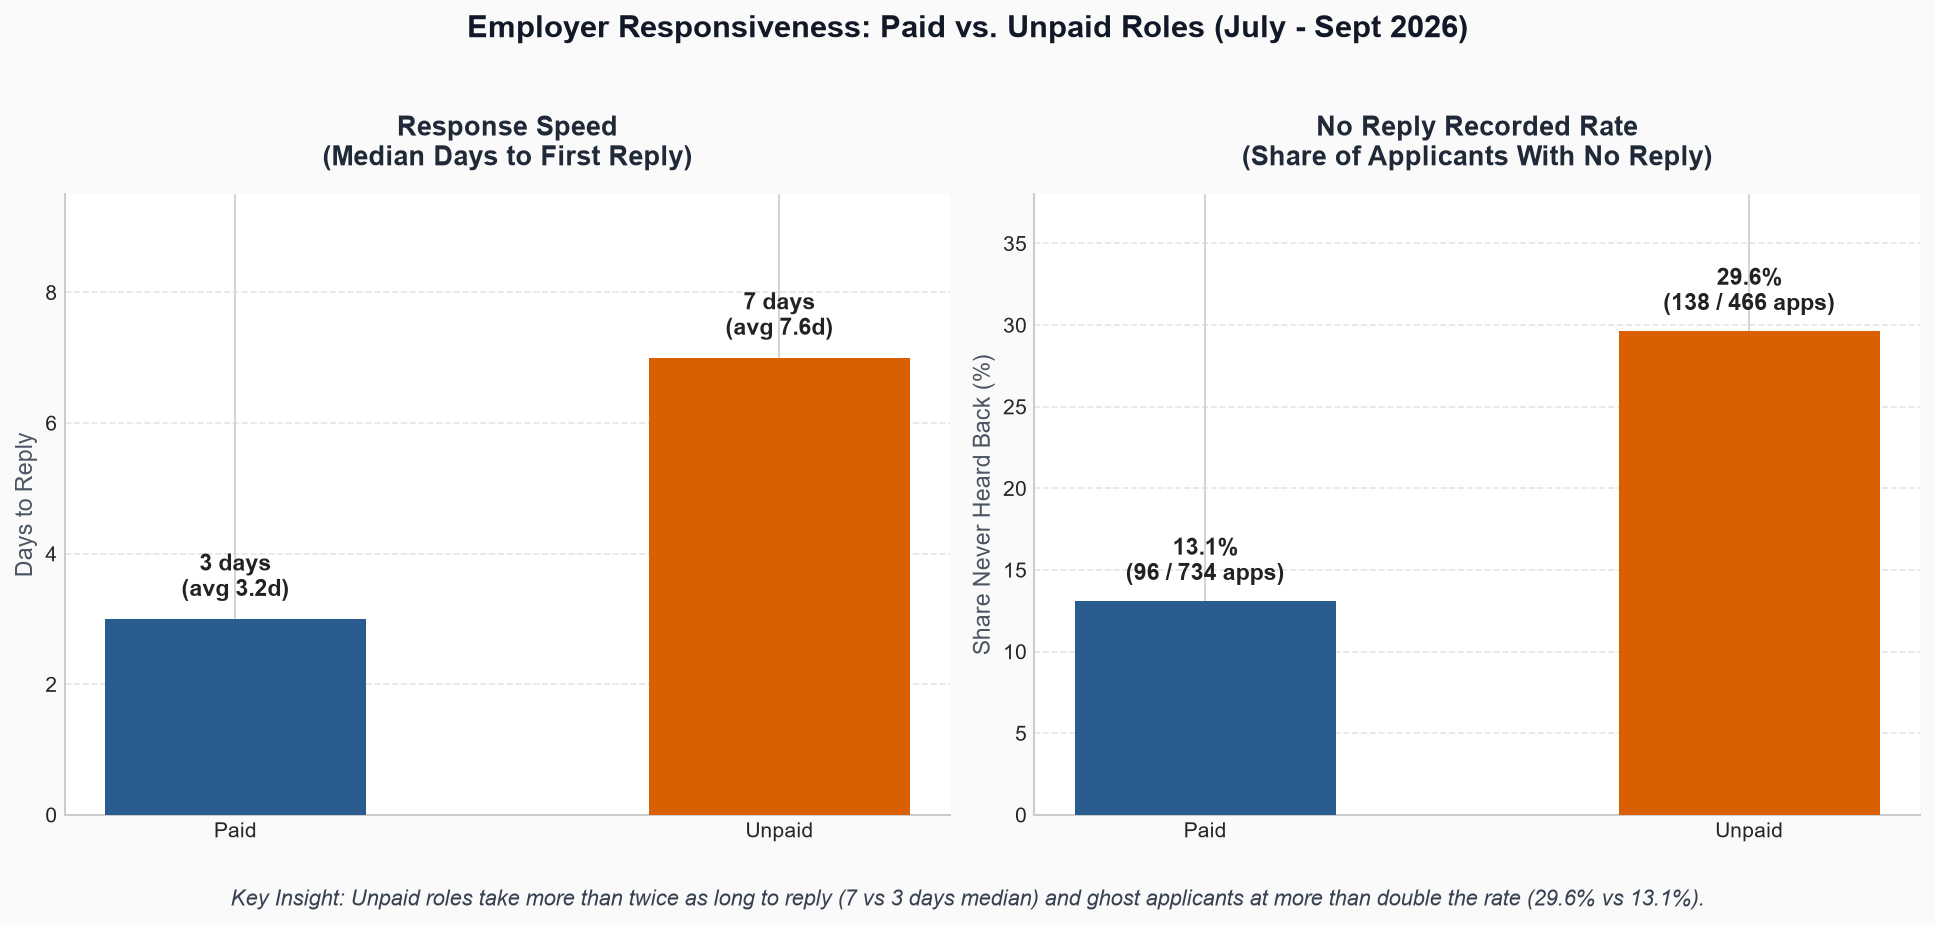

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
import os


plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)
fig.patch.set_facecolor('#fafafa')
colors = {'Paid': '#2b5c8f', 'Unpaid': '#d95f02'}

ax1.set_facecolor('#ffffff')
bars1 = ax1.bar(
    q3_results['role_type'], 
    q3_results['median_days'], 
    color=[colors[r] for r in q3_results['role_type']], 
    width=0.48, 
    edgecolor='none', 
    zorder=3
)

for bar in bars1:
    h = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2, 
        h + 0.25, 
        f"{h:.0f} days\n(avg {q3_results.loc[q3_results['role_type']==bar.get_x() if False else [0,1][bars1.index(bar)], 'mean_days']:.1f}d)", 
        ha='center', va='bottom', fontsize=11, fontweight='bold', color='#222222'
    )

ax1.set_title("Response Speed\n(Median Days to First Reply)", fontsize=13, fontweight='bold', pad=14, color='#1f2937')
ax1.set_ylabel("Days to Reply", fontsize=11, color='#4b5563')
ax1.set_ylim(0, 9.5)
ax1.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

ax2.set_facecolor('#ffffff')
bars2 = ax2.bar(
    q3_results['role_type'], 
    q3_results['never_heard_back_%'], 
    color=[colors[r] for r in q3_results['role_type']], 
    width=0.48, 
    edgecolor='none', 
    zorder=3
)

for bar in bars2:
    h = bar.get_height()
    ax2.text(
        bar.get_x() + bar.get_width() / 2, 
        h + 0.9, 
        f"{h:.1f}%\n({q3_results.loc[bars2.index(bar), 'never_heard_back']} / {q3_results.loc[bars2.index(bar), 'total_applications']} apps)", 
        ha='center', va='bottom', fontsize=11, fontweight='bold', color='#222222'
    )

ax2.set_title("No Reply Recorded Rate\n(Share of Applicants With No Reply)", fontsize=13, fontweight='bold', pad=14, color='#1f2937')
ax2.set_ylabel("Share Never Heard Back (%)", fontsize=11, color='#4b5563')
ax2.set_ylim(0, 38)
ax2.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.suptitle("Employer Responsiveness: Paid vs. Unpaid Roles (July - Sept 2026)", 
             fontsize=15, fontweight='bold', y=1.03, color='#111827')

fig.text(0.5, -0.05, 
         "Key Insight: Unpaid roles take more than twice as long to reply (7 vs 3 days median) and ghost applicants at more than double the rate (29.6% vs 13.1%).",
         ha='center', fontsize=10.5, style='italic', color='#374151')

plt.tight_layout()

os.makedirs('../outputs', exist_ok=True)
output_path = '../outputs/question_3_paid_vs_unpaid.png'
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Chart saved successfully to: {output_path}")
plt.show()